In [1]:
1/(0.1**2 * 1000)

0.09999999999999998

In [3]:
import numpy as np
x = np.random.randn(1000)
x

array([ 9.40372131e-02, -8.17910666e-01, -2.32873724e-01, -1.93047133e+00,
        1.36073742e+00,  9.55393752e-02,  2.36751762e-01,  1.64888172e-01,
       -3.25510506e-01,  4.15724065e-02, -2.08555259e-01, -8.95538652e-01,
       -4.44918485e-01,  2.63516265e-01,  9.80839179e-01, -3.36717244e-01,
        5.77249531e-01, -8.89873189e-01, -9.55189925e-01,  1.38844014e+00,
        1.53583494e+00,  1.79118011e-01, -9.62128377e-01,  1.31874537e+00,
        1.43284071e+00, -7.90071060e-01,  1.37758400e+00, -3.80981758e-01,
        3.78860305e-01,  1.44273616e-01,  1.48520434e+00,  1.52689113e+00,
        1.41270284e+00, -1.11833647e+00, -6.69674232e-01,  4.60804905e-01,
        6.12847808e-02, -2.14963072e-01,  5.34073450e-01, -1.61395225e-01,
       -1.30824691e-01,  6.08340818e-01, -1.06977965e+00, -2.91728424e-01,
        1.13921583e+00, -3.21526224e-01,  1.04332584e+00,  4.63363436e-01,
       -3.19751952e-01,  1.39488907e-01,  2.04709651e-01,  6.61919204e-02,
       -7.56971290e-01, -

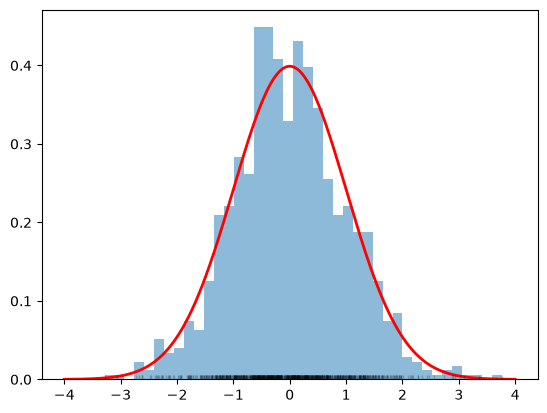

In [7]:
import matplotlib.pyplot as plt

plt.hist(x, bins=40, density=True, alpha=0.5, label="samples of x")

xs = np.linspace(-4,4, 400)
pdf = np.exp(-xs**2 / 2) / np.sqrt(2 * np.pi)
plt.plot(xs, pdf, 'r-', lw=2, label='N(0,1) pdf')

plt.plot(x, np.zeros_like(x), '|', color='k', alpha=0.2)

In [29]:
import math
vol = lambda D, r: ((r**D * np.pi**(D/2))/math.lgamma(D/2+1))

In [33]:
for k in range(4):
    D = 10**k
    print(D)
    v = vol(D, 0.5)
    print(v)

1
-7.337394494454608
10
0.06242253031009177
100
3.8267724703618543e-08
1000
1.3430087701472932e-56


# Problem 8.9

In [55]:
import sympy as sp
t = sp.symbols('t')
usual_integration = sp.integrate(sp.exp(-t**2/2), (t,-sp.oo, sp.oo))
sp.simplify(usual_integration)
cartesian = usual_integration**D
cartesian

(sqrt(2)*sqrt(pi))**D

With sperical shells

In [65]:
C_D = sp.symbols("C_D")
r = sp.symbols("r", positive=True)
D = sp.symbols("D", integer=True, positive=True)
spherical_shell_volume = sp.integrate(C_D*sp.exp(-r**2/2)*r**(D-1), (r, 0, sp.oo))
spherical_shell_volume

2**(D/2 - 1)*C_D*gamma(D/2)

In [66]:
eq = sp.Eq(spherical_shell_volume, cartesian)
C_D_sol = sp.solve(eq, C_D)[0]
C_D_sol

2*pi**(D/2)/gamma(D/2)

In [67]:
probability = (2*sp.pi)**(-D/2)*sp.exp(-r**2/2)*C_D_sol*r**(D-1)
sp.simplify(probability)

2**(1 - D/2)*r**(D - 1)*exp(-r**2/2)/gamma(D/2)